# SMR hydrogen plant (#473)

A steam-methane-reforming hydrogen plant in `difflow_refinery.hydrogen.smr`:

- ZnO guard, then an adiabatic prereformer.
- Reformer tubes with Xu & Froment (1989) kinetics, integrated by diffrax.
- HT shift, then a knock-out.
- PSA, with the furnace closing the reformer duty on tail gas plus supplementary natural gas.

This notebook covers:

1. One reformer tube and its temperature and composition profile.
2. The plant against the IEAGHG 2017/02 base case.
3. S/C and outlet-temperature trade-offs, with exact gradients.
4. The plant as a swing producer in the refinery hydrogen network.

Sources and what is ILLUSTRATIVE: `docs/unit-operations-refinery.md`, *SMR hydrogen plant: references*.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from difflow import make_stream
import difflow_refinery.hydrogen as h2
from difflow_refinery.hydrogen import smr

## 1. One reformer tube

The tube is a Xu & Froment Part II tube: 11.12 m heated length, 0.1016 m inside diameter, and effectiveness factors near 0.03. A uniform heat flux is solved so the outlet reaches 1123 K.

The cold dip at the inlet is the reforming endotherm outrunning the flux.

duty 88.3 kW, CH4 conversion 0.814, approach to equilibrium 3.0 K, mean flux 25 kW/m2


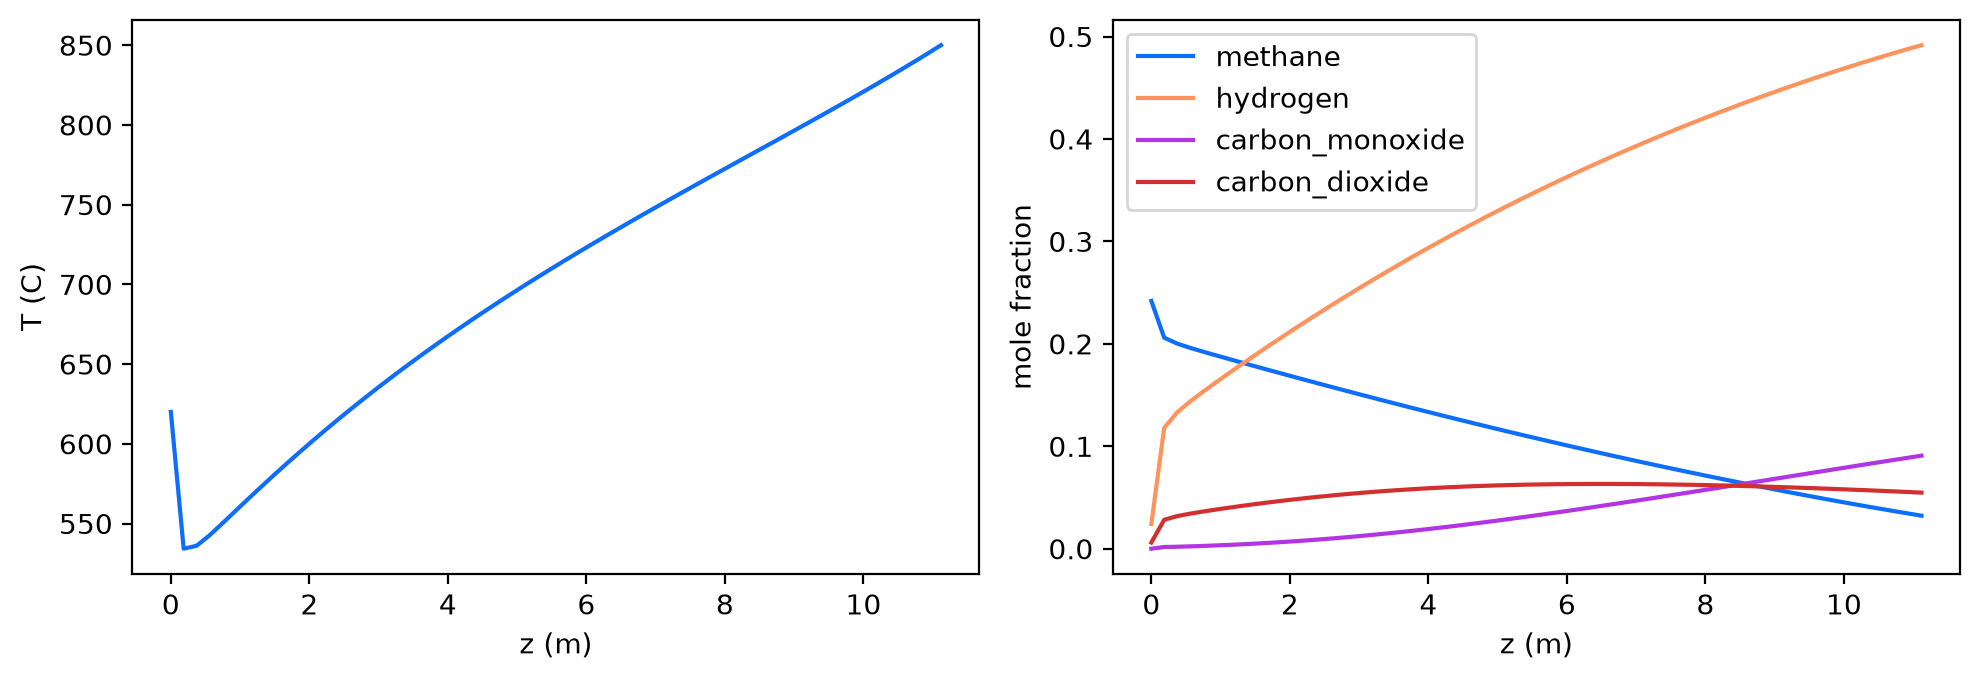

In [2]:
feed = make_stream({"methane": 0.4, "water": 1.2, "hydrogen": 0.04, "carbon_dioxide": 0.01,
                    "nitrogen": 0.004}, 893.15, 25e5)
out, info = smr.reformer_tube(feed, smr.ReformerTubeParams(), T_out=1123.15, n_profile=61)
prof = info["profile"]
z = np.asarray(prof["z"]); n = np.asarray(prof["n"]); y = n / n.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(z, np.asarray(prof["T"]) - 273.15); ax[0].set(xlabel="z (m)", ylabel="T (C)")
for k in ("methane", "hydrogen", "carbon_monoxide", "carbon_dioxide"):
    ax[1].plot(z, y[:, smr.SYNGAS.index(k)], label=k)
ax[1].set(xlabel="z (m)", ylabel="mole fraction"); ax[1].legend()
plt.tight_layout()
print(f"duty {float(info['Q'])/1e3:.1f} kW, CH4 conversion {float(info['CH4_conversion']):.3f}, "
      f"approach to equilibrium {float(info['approach']):.1f} K, mean flux {float(info['heat_flux'])/1e3:.0f} kW/m2")

## 2. The IEAGHG 2017/02 base case

The inputs are the report's natural gas at 1455.8 kmol/h, S/C 2.75 and a 920 °C outlet. The PSA recovery of 0.90 comes from the report's own streams.

Fuel is not compared: the combustion-air preheat temperature is not given, and the fuel moves with it.

In [3]:
y = {"methane": 0.89, "ethane": 0.07, "propane": 0.01, "n_butane": 0.0011,
     "carbon_dioxide": 0.02, "nitrogen": 0.0089, "hydrogen_sulfide": 5e-6}
ng = make_stream({k: v * 1455.8 / 3.6 for k, v in y.items()}, 401.15, 3.71e6)
p = smr.SMRParams(n_tubes=240, psa=h2.PSA(recovery=0.90, purity=0.9999))
r = smr.smr_plant(ng, p)
ko = smr.to_vec(r["ko"])
rows = [("H2 product + recycle, kmol/h", 4490.6, float(r["H2"]) * 3.6),
        ("CH4 slip, dry %", "3.3-4", 100 * float(r["CH4_slip"])),
        ("radiant duty, MW", 96.1, float(r["reformer_duty"]) / 1e6),
        ("HTS outlet, C", 412, float(r["hts"]["T"]) - 273.15),
        ("PSA inlet H2, %", 75.63, 100 * float(ko[2] / ko.sum()))]
for name, ref, ours in rows:
    print(f"{name:32s} {str(ref):>8s} {ours:10.2f}")
print(f"\nCO2 {float(r['CO2_per_H2']):.2f} kg/kg H2, efficiency {float(r['efficiency']):.3f} (LHV, no steam credit)")

H2 product + recycle, kmol/h       4490.6    4455.50
CH4 slip, dry %                     3.3-4       3.57
radiant duty, MW                     96.1      98.26
HTS outlet, C                         412     412.28
PSA inlet H2, %                     75.63      75.52

CO2 9.44 kg/kg H2, efficiency 0.724 (LHV, no steam credit)


## 3. Trade-offs, with exact gradients

More steam and a hotter outlet both cut the methane slip. They cost fuel and duty in return. The derivatives come from `jax.jacfwd` through the tube ODE, the duty solve, the Gibbs reactors and the furnace.

In [4]:
def plant(x):
    q = smr.SMRParams(S_C=x[0], T_out=x[1], psa=h2.PSA(recovery=0.90, purity=0.9999),
                      tube=smr.ReformerTubeParams(adjoint="forward"))
    one = make_stream({k: v * 0.45 for k, v in y.items()}, 401.15, 3.71e6)   # one tube's worth
    s = smr.smr_plant(one, q)
    return jnp.stack([s["H2"], s["CH4_slip"], s["CO2"], s["ng_lhv"] / s["H2"] / 1e3])

x0 = jnp.array([2.75, 1193.15])
J = jax.jacfwd(plant)(x0)
names = ["H2 (mol/s)", "CH4 slip", "CO2 (mol/s)", "NG LHV per H2 (kJ/mol)"]
for i, nme in enumerate(names):
    print(f"{nme:24s} d/dS_C = {float(J[i, 0]): .4e}   d/dT_out = {float(J[i, 1]): .4e} /K")

H2 (mol/s)               d/dS_C =  1.5556e-01   d/dT_out =  2.0727e-03 /K
CH4 slip                 d/dS_C = -2.0859e-02   d/dT_out = -4.1118e-04 /K
CO2 (mol/s)              d/dS_C =  7.3476e-02   d/dT_out =  1.0246e-03 /K
NG LHV per H2 (kJ/mol)   d/dS_C =  3.4720e+00   d/dT_out =  7.1458e-02 /K


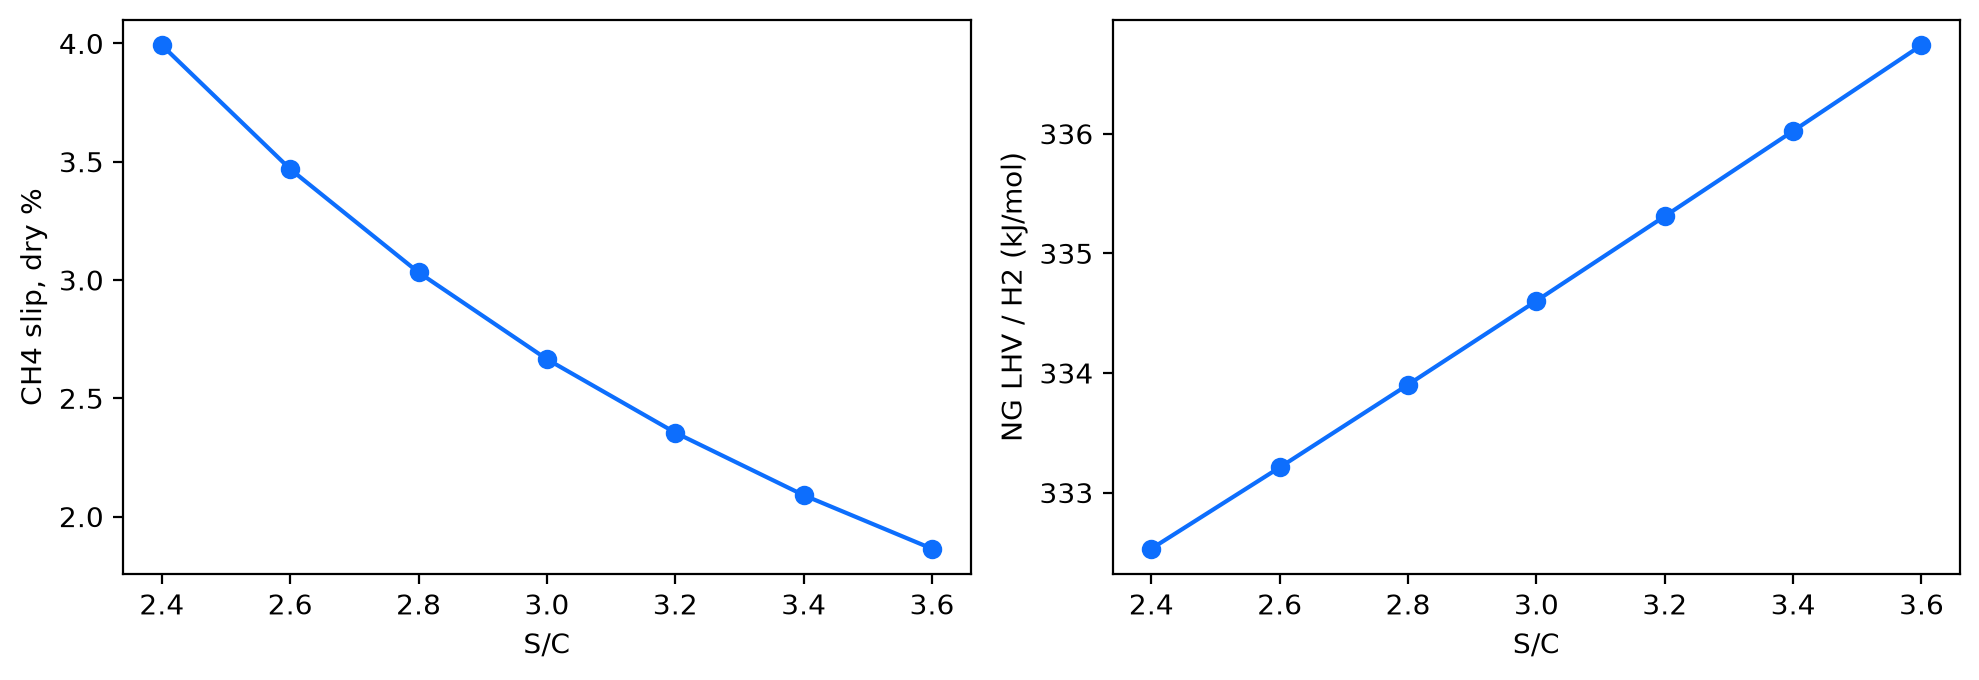

In [5]:
SC = np.linspace(2.4, 3.6, 7)
res = np.array([np.asarray(plant(jnp.array([s, 1193.15]))) for s in SC])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(SC, 100 * res[:, 1], "o-"); ax[0].set(xlabel="S/C", ylabel="CH4 slip, dry %")
ax[1].plot(SC, res[:, 3], "o-"); ax[1].set(xlabel="S/C", ylabel="NG LHV / H2 (kJ/mol)")
plt.tight_layout()

## 4. Into the hydrogen network

`H2Plant.from_smr` makes the plant a swing producer. Its capacity, purity and marginal cost come from the plant result.

In [6]:
plant_h2 = h2.H2Plant.from_smr(r, ng_price=4.0)
net = h2.HydrogenNetwork(
    producers=[h2.Producer.of_purity("reformer", 900.0, 0.85)],
    consumers=[h2.Consumer("dht", 1500.0, min_purity=0.85), h2.Consumer("nht", 600.0, min_purity=0.85)],
    headers=[h2.Header("main", swing=[plant_h2])])
res = net.solve()
print(f"SMR capacity {float(plant_h2.capacity):.0f} mol/s at {float(plant_h2.marginal_cost):.2f} $/kmol; "
      f"surplus {float(res.outputs['h2.surplus']):.1f} mol/s")
{k: float(v) for k, v in res.outputs.items() if k.startswith(("main", "dht", "swing"))}

SMR capacity 1238 mol/s at 1.34 $/kmol; surplus 0.0 mol/s


{'dht.makeup_h2': 1500.0,
 'dht.makeup_mol_s': 1613.5311010092605,
 'dht.makeup_nm3_h': 121035.4355408456,
 'dht.purity': 0.9296381080363142,
 'dht.purity_margin': 0.07963810803631421,
 'main.purity': 0.9296381080363142,
 'main.loop_residual': 0.0,
 'main.h2_supply': 2100.0,
 'main.h2_demand': 2100.0,
 'main.h2_surplus': 0.0,
 'main.purge_mol_s': 0.0,
 'swing.h2': 1200.0}